<a href="https://colab.research.google.com/github/MAI-AIIU/mathematics-foundation/blob/main/src/eighth-week/vector-calculus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Vector Calculus

# Laboratory 4: Vector Calculus using PyTorch

---

## Topics

1. Differentiation of Univariate Functions
2. Partial Differentiation and Gradients
3. Gradients of Vector-Valued Functions

## Environment

- PyTorch
- Matplotlib
- Jupyter Notebook or Google Colab

Synthetic examples only; no external dataset, NumPy, or D2L package is required.

---

## Learning Objectives and Conventions

- Compute first and higher derivatives with PyTorch autograd and verify them numerically.
- Interpret gradients, Jacobians, Hessians, and matrix gradients with correct shapes.
- Apply chain, product, trace, quadratic-form, and inverse-related gradient identities.

<!-- **Shape convention.** For $f:\mathbb{R}^n\to\mathbb{R}$, we display the gradient as a column vector; PyTorch returns it with the same shape as its input. The Jacobian of $F:\mathbb{R}^n\to\mathbb{R}^m$ has shape $(m,n)$, with outputs in rows and inputs in columns. For a scalar function of a matrix $W$, the gradient has the same shape as $W$ and satisfies $df=\langle\nabla_Wf,dW\rangle_F$. -->



## Setup

PyTorch handles tensors, differentiation, and optimization. Matplotlib is only used for visualizations.

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(17)
torch.set_printoptions(precision=5, sci_mode=False)
DTYPE = torch.float64

# 1. Differentiation of Univariate Functions

For $f:\mathbb{R}\to\mathbb{R}$, the derivative is the limit of the difference quotient

$$f'(x)=\lim_{h\to 0}\frac{f(x+h)-f(x)}{h}.$$

A small perturbation obeys $f(x+\Delta x)\approx f(x)+f'(x)\Delta x$. Product and chain rules differentiate compositions. Automatic differentiation applies these rules to operations in the executed program, producing derivatives to floating-point precision; it is neither symbolic differentiation nor finite-difference approximation.

## 1.1 Analytic, Autograd, and Finite-Difference Derivatives

For $f(x)=x^3-2x^2+\sin x$, compare its analytic derivative with PyTorch autograd and a centered finite difference. This check is a useful pattern for custom loss code.

In [2]:
def f(x):
    return x**3 - 2 * x**2 + torch.sin(x)

x0 = torch.tensor(1.2, dtype=DTYPE, requires_grad=True)
y0 = f(x0)
df_autograd = torch.autograd.grad(y0, x0)[0]
df_analytic = 3 * x0.detach().square() - 4 * x0.detach() + torch.cos(x0.detach())
h = 1e-5
with torch.no_grad():
    df_finite = (f(x0 + h) - f(x0 - h)) / (2 * h)
print(f"f(x0)               = {y0.item():.8f}")
print(f"autograd derivative = {df_autograd.item():.8f}")
print(f"analytic derivative = {df_analytic.item():.8f}")
print(f"centered difference = {df_finite.item():.8f}")
assert torch.allclose(df_autograd, df_analytic, atol=1e-12)
assert torch.allclose(df_autograd, df_finite, atol=1e-8)

f(x0)               = -0.21996091
autograd derivative = -0.11764225
analytic derivative = -0.11764225
centered difference = -0.11764225


## 1.2 Chain Rule in a Neuron and Binary Cross-Entropy

A logistic neuron computes $p=\sigma(z)$. For binary target $y$, binary cross-entropy simplifies under the chain rule to $d\ell/dz=p-y$. This is the learning signal used by logistic regression and binary classifiers.

In [6]:
z = torch.tensor(-0.4, dtype=DTYPE, requires_grad=True)
target = torch.tensor(1.0, dtype=DTYPE)
probability = torch.sigmoid(z)
loss = -(target * torch.log(probability) + (1 - target) * torch.log(1 - probability))
dloss_dz = torch.autograd.grad(loss, z)[0]
print(f"probability = {probability.item():.6f}")
print(f"autograd d(loss)/dz = {dloss_dz.item():.6f}")
print(f"p - y              = {(probability - target).item():.6f}")
assert torch.allclose(dloss_dz, probability.detach() - target, atol=1e-12)

probability = 0.401312
autograd d(loss)/dz = -0.598688
p - y              = -0.598688


<!-- ### Check Your Understanding

1. Differentiate $g(x)=e^{2x}\cos x$ by hand and verify with autograd.
2. Compare forward and centered differences over several step sizes. Why can a tiny step increase rounding error?
3. For binary cross-entropy, explain why the logit gradient changes sign when the prediction is on the wrong side of the target. -->

# 2. Partial Differentiation and Gradients

For $f:\mathbb{R}^n\to\mathbb{R}$, the gradient collects the partial derivatives:

$$\nabla f(x)=\begin{bmatrix}\partial f/\partial x_1&\cdots&\partial f/\partial x_n\end{bmatrix}^T.$$

For unit direction $u$, the directional derivative is $D_uf=\nabla f^Tu$. The gradient points toward steepest local increase; its negative is the steepest local decrease direction. The multivariable chain rule composes Jacobians in the order dictated by their shapes.

## 2.1 Quadratic Objective and Gradient Descent

For $f(x)=\tfrac12x^TAx+b^Tx$, the gradient is $\tfrac12(A+A^T)x+b$; for symmetric $A$ this is $Ax+b$. Quadratics are local models for loss landscapes and standard test problems for optimizers.

In [7]:
A = torch.tensor([[4.0, 1.0], [1.0, 3.0]], dtype=DTYPE)
b = torch.tensor([-1.0, 0.5], dtype=DTYPE)
x = torch.tensor([0.8, -1.1], dtype=DTYPE, requires_grad=True)
quadratic = 0.5 * x @ A @ x + b @ x
grad_x = torch.autograd.grad(quadratic, x)[0]
grad_x_analytic = A @ x.detach() + b
print("f(x) =", quadratic.item())
print("autograd gradient =", grad_x)
print("analytic gradient =", grad_x_analytic)
assert torch.allclose(grad_x, grad_x_analytic, atol=1e-12)

f(x) = 0.8649999999999998
autograd gradient = tensor([ 1.10000, -2.00000], dtype=torch.float64)
analytic gradient = tensor([ 1.10000, -2.00000], dtype=torch.float64)


## 2.2 Directional Derivative

Check the gradient-dot-direction formula by perturbing the input along a normalized vector.

In [10]:
direction = torch.tensor([2.0, -1.0], dtype=DTYPE)
direction = direction / torch.linalg.norm(direction)
h = 1e-5
with torch.no_grad():
    f_plus = 0.5 * (x + h * direction) @ A @ (x + h * direction) + b @ (x + h * direction)
    f_minus = 0.5 * (x - h * direction) @ A @ (x - h * direction) + b @ (x - h * direction)
directional_fd = (f_plus - f_minus) / (2 * h)
directional_ad = grad_x @ direction
print(f"gradient dot direction = {directional_ad.item():.8f}")
print(f"centered difference    = {directional_fd.item():.8f}")
assert torch.allclose(directional_ad, directional_fd, atol=1e-8)

gradient dot direction = 1.87829710
centered difference    = 1.87829710


## 2.3 Application: Train Linear Regression with Gradients

For $X\in\mathbb{R}^{N\times d}$, weights $w$, targets $y$, and $L(w)=\|Xw-y\|^2/(2N)$, the gradient is $X^T(Xw-y)/N$. Fit synthetic data by gradient descent and compare with least squares.

In [11]:
torch.manual_seed(23)
num_examples, num_features = 160, 3
X_train = torch.randn(num_examples, num_features, dtype=DTYPE)
true_weights = torch.tensor([1.5, -2.0, 0.7], dtype=DTYPE)
y_train = X_train @ true_weights + 0.25 + 0.05 * torch.randn(num_examples, dtype=DTYPE)
weights = torch.zeros(num_features, dtype=DTYPE, requires_grad=True)
learning_rate = 0.2
loss_history = []
for _ in range(120):
    train_loss = 0.5 * (X_train @ weights - y_train).square().mean()
    gradient = torch.autograd.grad(train_loss, weights)[0]
    with torch.no_grad():
        weights -= learning_rate * gradient
    loss_history.append(train_loss.item())
least_squares = torch.linalg.lstsq(X_train, y_train).solution
print("gradient-descent weights =", weights.detach())
print("least-squares weights    =", least_squares)
print(f"final MSE = {(X_train @ weights.detach() - y_train).square().mean().item():.6f}")
assert torch.allclose(weights.detach(), least_squares, atol=2e-2)

gradient-descent weights = tensor([ 1.47805, -1.98181,  0.70805], dtype=torch.float64)
least-squares weights    = tensor([ 1.47805, -1.98181,  0.70805], dtype=torch.float64)
final MSE = 0.068605


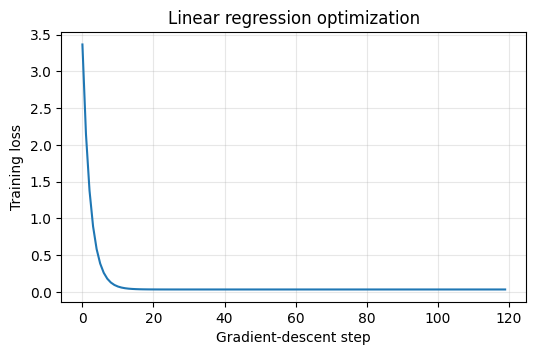

In [12]:
plt.figure(figsize=(6, 3.5))
plt.plot(loss_history)
plt.xlabel("Gradient-descent step")
plt.ylabel("Training loss")
plt.title("Linear regression optimization")
plt.grid(alpha=0.3)
plt.show()

# 3. Gradients of Vector-Valued Functions

For $F:\mathbb{R}^n\to\mathbb{R}^m$, its Jacobian $J_F\in\mathbb{R}^{m\times n}$ has entries $(J_F)_{ij}=\partial F_i/\partial x_j$. Each row corresponds to one output. For a composition $G(F(x))$, $J_{G\circ F}=J_GJ_F$.

## 3.1 Jacobian and the Multivariable Chain Rule

For $F(x_1,x_2)=[x_1^2+x_2,\;x_1x_2,\;\sin x_1]^T$, compute its Jacobian, check its shape and entries, then propagate a scalar loss through $F$ using the chain rule.

In [13]:
def vector_function(inputs):
    x1, x2 = inputs[0], inputs[1]
    return torch.stack((x1.square() + x2, x1 * x2, torch.sin(x1)))

inputs = torch.tensor([0.7, -0.3], dtype=DTYPE, requires_grad=True)
outputs = vector_function(inputs)
jacobian = torch.autograd.functional.jacobian(vector_function, inputs)
jacobian_expected = torch.stack((
    torch.stack((2 * inputs[0].detach(), torch.ones((), dtype=DTYPE))),
    torch.stack((inputs[1].detach(), inputs[0].detach())),
    torch.stack((torch.cos(inputs[0].detach()), torch.zeros((), dtype=DTYPE))),
))
print("F(x) =", outputs)
print("Jacobian shape =", tuple(jacobian.shape))
print("J_F(x) =\n", jacobian)
assert jacobian.shape == (3, 2)
assert torch.allclose(jacobian, jacobian_expected, atol=1e-12)

F(x) = tensor([ 0.19000, -0.21000,  0.64422], dtype=torch.float64,
       grad_fn=<StackBackward0>)
Jacobian shape = (3, 2)
J_F(x) =
 tensor([[ 1.40000,  1.00000],
        [-0.30000,  0.70000],
        [ 0.76484,  0.00000]], dtype=torch.float64)


In [14]:
output_weights = torch.tensor([0.5, -1.0, 2.0], dtype=DTYPE)
scalar_loss = output_weights @ vector_function(inputs)
grad_from_autograd = torch.autograd.grad(scalar_loss, inputs)[0]
grad_from_chain_rule = jacobian.T @ output_weights
print("autograd gradient =", grad_from_autograd)
print("J_F^T output weights =", grad_from_chain_rule)
assert torch.allclose(grad_from_autograd, grad_from_chain_rule, atol=1e-12)

autograd gradient = tensor([ 2.52968, -0.20000], dtype=torch.float64)
J_F^T output weights = tensor([ 2.52968, -0.20000], dtype=torch.float64)


## 3.2 Jacobian-Vector and Vector-Jacobian Products

A full Jacobian may be too large to construct. Forward mode computes $Jv$; reverse mode computes $J^Tw$. For scalar losses with many inputs, reverse mode is often the efficient choice.

In [15]:
input_direction = torch.tensor([0.2, -0.4], dtype=DTYPE)
_, jvp = torch.autograd.functional.jvp(vector_function, inputs.detach(), input_direction)
_, vjp = torch.autograd.functional.vjp(
    vector_function, inputs.detach(), v=output_weights
)
print("Jv from autograd =", jvp)
print("Jv from matrix   =", jacobian @ input_direction)
print("J^T w from autograd =", vjp)
print("J^T w from matrix   =", jacobian.T @ output_weights)
assert torch.allclose(jvp, jacobian @ input_direction, atol=1e-12)
assert torch.allclose(vjp, jacobian.T @ output_weights, atol=1e-12)

Jv from autograd = tensor([-0.12000, -0.34000,  0.15297], dtype=torch.float64)
Jv from matrix   = tensor([-0.12000, -0.34000,  0.15297], dtype=torch.float64)
J^T w from autograd = tensor([ 2.52968, -0.20000], dtype=torch.float64)
J^T w from matrix   = tensor([ 2.52968, -0.20000], dtype=torch.float64)


## 3.3 Batch Outputs and Neural-Network Layers

A batch loss usually requires an aggregate parameter gradient, not a full Jacobian tensor for every example. Autograd sums the contributions through the graph.

In [16]:
layer = torch.nn.Linear(3, 2, bias=True, dtype=DTYPE)
batch = torch.randn(4, 3, dtype=DTYPE)
labels = torch.randn(4, 2, dtype=DTYPE)
layer_loss = 0.5 * (layer(batch) - labels).square().mean()
layer_loss.backward()
print("input batch shape =", tuple(batch.shape))
print("output batch shape =", tuple(layer(batch).shape))
print("weight shape =", tuple(layer.weight.shape))
print("weight gradient shape =", tuple(layer.weight.grad.shape))

input batch shape = (4, 3)
output batch shape = (4, 2)
weight shape = (2, 3)
weight gradient shape = (2, 3)


## Summary

- Derivatives and gradients measure how objectives change with inputs and parameters.
- Jacobians organize derivatives of vector-valued functions; matrix gradients follow the same chain rule with tensor-aware shapes.


## Exercises

<!-- 1. Implement a finite-difference checker for each coordinate of a tensor parameter and compare it with autograd. -->
1. Derive and verify the gradient of $L(w)=\|Xw-y\|^2/(2N)+\lambda\|w\|^2/2$. How does weight decay change the optimum?
<!-- 3. For a two-layer ReLU network, compare analytic, autograd, and finite-difference gradients away from activation boundaries. What happens at a ReLU kink? -->

2. Compute the Jacobian of batch normalization for two examples. How does coupling examples change the Jacobian?
<!-- 5. Verify $\nabla_X\operatorname{tr}(X^TX)=2X$ and the gradient of $\log\det X$ for positive-definite $X$.
6. Use Hessian-vector products to compute a Newton direction for a quadratic objective. Compare memory with explicitly forming the Hessian.
7. Use a second-order Taylor model as a local surrogate for a neural-network loss. Find the largest perturbation radius whose approximation error is below a chosen tolerance. -->

## Solutions

<!-- 1. Implement a finite-difference checker for each coordinate of a tensor parameter and compare it with autograd. -->
1. Derive and verify the gradient of $L(w)=\|Xw-y\|^2/(2N)+\lambda\|w\|^2/2$. How does weight decay change the optimum?
<!-- 3. For a two-layer ReLU network, compare analytic, autograd, and finite-difference gradients away from activation boundaries. What happens at a ReLU kink? -->

In [28]:
import torch

X = torch.tensor([
    [1., 2.],
    [2., 3.],
    [3., 4.]
], dtype=torch.float64)

y = torch.tensor([5., 8., 11.], dtype=torch.float64)

w = torch.tensor([1., 2.], dtype=torch.float64, requires_grad=True)

N = X.shape[0]
lam = 0.1

In [19]:
def loss(w, lam):
    prediction_loss = (X @ w - y).square().sum() / (2 * N)
    regularization = lam * w.square().sum() / 2

    return prediction_loss + regularization

In [20]:
L = loss(w, lam)

grad_autograd = torch.autograd.grad(L, w)[0]

print(grad_autograd)

tensor([0.10000, 0.20000], dtype=torch.float64)


In [21]:
L = loss(w, lam)

grad_autograd = torch.autograd.grad(L, w)[0]

print(grad_autograd)

tensor([0.10000, 0.20000], dtype=torch.float64)


In [23]:
grad_analytic = X.T @ (X @ w - y) / N + lam * w

print(grad_analytic)

assert torch.allclose(grad_autograd, grad_analytic)

tensor([0.10000, 0.20000], dtype=torch.float64, grad_fn=<AddBackward0>)


In [25]:
I = torch.eye(X.shape[1], dtype=DTYPE)

def optimum(lam):
    return torch.linalg.solve(
        X.T @ X + N * lam * I,
        X.T @ y
    )

In [26]:
for lam in [0.0, 0.01, 0.1, 1.0, 10.0]:
    w_opt = optimum(lam)

    print(
        f"Lambda: {lam:5.2f}, "
        f"Weights: {w_opt.tolist()}, "
        f"Norm: {w_opt.norm().item():.4f}"
    )

Lambda:  0.00, Weights: [1.0000000000000042, 1.9999999999999971], Norm: 2.2361
Lambda:  0.01, Weights: [1.0451384602723996, 1.9668353701189116], Norm: 2.2273
Lambda:  0.10, Weights: [1.1690363349131108, 1.8641390205371258], Norm: 2.2004
Lambda:  1.00, Weights: [1.1666666666666667, 1.7083333333333333], Norm: 2.0687
Lambda: 10.00, Weights: [0.7404371584699454, 1.0710382513661203], Norm: 1.3021


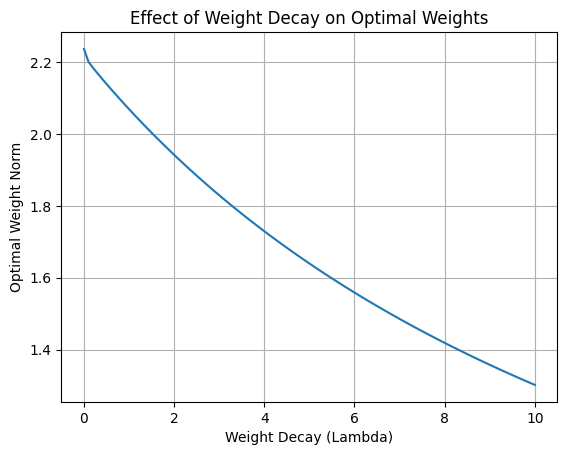

In [27]:
import matplotlib.pyplot as plt

lambdas = torch.linspace(0, 10, 100)
norms = [optimum(lam).norm().item() for lam in lambdas]

plt.plot(lambdas, norms)
plt.xlabel("Weight Decay (Lambda)")
plt.ylabel("Optimal Weight Norm")
plt.title("Effect of Weight Decay on Optimal Weights")
plt.grid()
plt.show()

2. Compute the Jacobian of batch normalization for two examples. How does coupling examples change the Jacobian?

In [31]:
import torch

x = torch.tensor([2.0, 4.0], dtype=torch.float64,
                 requires_grad=True)

def batch_norm(x):
    mean = x.mean()
    var = x.var(unbiased=False)
    return (x - mean) / torch.sqrt(var + 1e-5)

print(batch_norm(x))

tensor([-1.00000,  1.00000], dtype=torch.float64, grad_fn=<DivBackward0>)


In [33]:
J = torch.autograd.functional.jacobian(batch_norm, x)

# without this precision it will print all zeros
torch.set_printoptions(precision=12, sci_mode=True)
print(J)

tensor([[ 4.999925000915e-06, -4.999925000915e-06],
        [-4.999925000915e-06,  4.999925000915e-06]], dtype=torch.float64)
